## 0. Persiapan Lingkungan dan Dataset

In [1]:
# ==== IDENTITAS (ubah sesuai data Anda) ====
NAMA  = "Khansa Nisrina"
NIM   = "2330511089"          # SEED = 4 digit terakhir NIM
KELAS = "TI-7B"

import os, sys
SEED = int(NIM[-4:])
DI_COLAB = "google.colab" in sys.modules
ROOT = f"/content/simuteh-{NIM}" if DI_COLAB else os.path.abspath(f"simuteh-{NIM}")
for sub in ["data", "notebook", "src", "hasil", "laporan"]:
    os.makedirs(os.path.join(ROOT, sub), exist_ok=True)
os.chdir(ROOT)
print("Folder kerja :", ROOT)
print("SEED         :", SEED)

Folder kerja : /content/simuteh-2330511089
SEED         : 1089


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
%%writefile src/buat_dataset_sintetis.py
"""
buat_dataset_sintetis.py
Membangkitkan dataset citra sintetis daun teh untuk studi kasus SIMUTEH.
Setiap mahasiswa memakai SEED = 4 digit terakhir NIM sehingga datanya berbeda.

Keluaran (folder data/sintetis/):
  citra/    citra berwarna hasil "pemotretan" (dengan gangguan cahaya dan derau)
  bersih/   citra yang sama tanpa gangguan (acuan mutu)
  mask_daun/    mask area daun (255 = daun)
  mask_bercak/  mask area bercak penyakit (255 = bercak)
  label.csv     nama_file, kelas, kondisi_cahaya, persen_bercak
"""
import os
import csv
import cv2
import numpy as np

SEED = 1089          # GANTI dengan 4 digit terakhir NIM Anda
N_PER_KELAS = 20     # 20 citra x 3 kelas = 60 citra
H, W = 480, 640
KELAS = ["sehat", "ringan", "berat"]
KONDISI = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
OUT = os.path.join("data", "sintetis")

rng = np.random.default_rng(SEED)


def gambar_daun(img, mask):
    """Menggambar satu helai daun berbentuk elips beserta tulang daunnya."""
    cx = int(rng.integers(260, 380))
    cy = int(rng.integers(200, 280))
    ax = int(rng.integers(190, 240))
    ay = int(rng.integers(95, 125))
    sudut = float(rng.uniform(-25, 25))
    hijau = np.array([rng.integers(35, 60), rng.integers(120, 150),
                      rng.integers(45, 75)])               # BGR
    cv2.ellipse(img, (cx, cy), (ax, ay), sudut, 0, 360, hijau.tolist(), -1)
    cv2.ellipse(mask, (cx, cy), (ax, ay), sudut, 0, 360, 255, -1)
    # tulang daun utama dan cabang
    t = np.deg2rad(sudut)
    p1 = (int(cx - ax * np.cos(t)), int(cy - ax * np.sin(t)))
    p2 = (int(cx + ax * np.cos(t)), int(cy + ax * np.sin(t)))
    tulang = (hijau * 1.35).clip(0, 255).tolist()
    cv2.line(img, p1, p2, tulang, 3)
    for k in np.linspace(-0.7, 0.7, 6):
        bx, by = cx + k * ax * np.cos(t), cy + k * ax * np.sin(t)
        for arah in (-1, 1):
            ex = bx + 0.35 * ax * np.cos(t + arah * 1.0)
            ey = by + 0.35 * ax * np.sin(t + arah * 1.0)
            cv2.line(img, (int(bx), int(by)), (int(ex), int(ey)), tulang, 1)
    return mask


def gambar_bercak(img, mask_daun, mask_bercak, kelas):
    """Menambahkan bercak cacar daun (pucat kekuningan, tepi kecokelatan)."""
    if kelas == "sehat":
        return
    n = int(rng.integers(1, 4)) if kelas == "ringan" else int(rng.integers(6, 13))
    r_min, r_maks = (3, 7) if kelas == "ringan" else (5, 14)
    ys, xs = np.where(mask_daun > 0)
    for _ in range(n):
        i = int(rng.integers(0, len(xs)))
        r = int(rng.integers(r_min, r_maks + 1))
        pusat = (int(xs[i]), int(ys[i]))
        warna = [int(rng.integers(70, 100)), int(rng.integers(165, 190)),
                 int(rng.integers(185, 210))]               # BGR pucat
        cv2.circle(img, pusat, r + 2, (40, 80, 110), -1)    # tepi cokelat
        cv2.circle(img, pusat, r, warna, -1)
        cv2.circle(mask_bercak, pusat, r + 2, 255, -1)
    mask_bercak &= mask_daun                                # bercak hanya di daun


def ganggu_cahaya(img, kondisi):
    """Mensimulasikan kondisi pemotretan di lapangan."""
    f = img.astype(np.float32)
    if kondisi == "gelap":
        f = 255 * (f / 255) ** 2.0
    elif kondisi == "terang":
        f = 255 * (f / 255) ** 0.45
    elif kondisi == "kontras_rendah":
        f = 0.35 * f + 95
    elif kondisi == "bayangan":
        gx = np.linspace(1.15, 0.30, W, dtype=np.float32)   # separuh teduh
        f = f * gx[None, :, None]
    sigma = float(rng.uniform(6, 14))
    f = f + rng.normal(0, sigma, f.shape)                   # derau sensor
    return np.clip(f, 0, 255).astype(np.uint8)


def main():
    for sub in ["citra", "bersih", "mask_daun", "mask_bercak"]:
        os.makedirs(os.path.join(OUT, sub), exist_ok=True)
    baris = []
    nomor = 0
    for kelas in KELAS:
        for j in range(N_PER_KELAS):
            nomor += 1
            latar = np.array([rng.integers(150, 190), rng.integers(170, 205),
                              rng.integers(185, 215)])      # nampan anyaman
            img = np.ones((H, W, 3), np.uint8) * latar.astype(np.uint8)
            img = cv2.add(img, rng.integers(0, 12, (H, W, 3)).astype(np.uint8))
            m_daun = np.zeros((H, W), np.uint8)
            m_bercak = np.zeros((H, W), np.uint8)
            gambar_daun(img, m_daun)
            gambar_bercak(img, m_daun, m_bercak, kelas)
            bersih = cv2.GaussianBlur(img, (3, 3), 0.8)
            kondisi = KONDISI[j % len(KONDISI)]
            citra = ganggu_cahaya(bersih, kondisi)
            nama = f"teh_{nomor:03d}.png"
            cv2.imwrite(os.path.join(OUT, "citra", nama), citra)
            cv2.imwrite(os.path.join(OUT, "bersih", nama), bersih)
            cv2.imwrite(os.path.join(OUT, "mask_daun", nama), m_daun)
            cv2.imwrite(os.path.join(OUT, "mask_bercak", nama), m_bercak)
            persen = 100 * (m_bercak > 0).sum() / max((m_daun > 0).sum(), 1)
            baris.append([nama, kelas, kondisi, round(persen, 2)])
    with open(os.path.join(OUT, "label.csv"), "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["nama_file", "kelas", "kondisi_cahaya", "persen_bercak"])
        w.writerows(baris)
    print(f"Selesai: {nomor} citra tersimpan di {OUT}")


if __name__ == "__main__":
    main()


Writing src/buat_dataset_sintetis.py


In [5]:
# Pasang SEED sesuai NIM, bangkitkan dataset, lalu pindah ke folder notebook/
import re, subprocess
kode = open("src/buat_dataset_sintetis.py").read()
kode = re.sub(r"^SEED = \d+", f"SEED = {SEED}", kode, count=1, flags=re.M)
open("src/buat_dataset_sintetis.py", "w").write(kode)
keluaran = subprocess.run([sys.executable, "src/buat_dataset_sintetis.py"],
                          capture_output=True, text=True)
print(keluaran.stdout, keluaran.stderr)

# requirements.txt untuk reprodusibilitas
import cv2, numpy, pandas, matplotlib, skimage, PIL
with open("requirements.txt", "w") as f:
    for nm, m in [("opencv-python", cv2), ("numpy", numpy), ("pandas", pandas),
                  ("matplotlib", matplotlib), ("scikit-image", skimage), ("pillow", PIL)]:
        f.write(f"{nm}=={m.__version__}\n")
print(open("requirements.txt").read())

os.chdir(os.path.join(ROOT, "notebook"))   # semua jalur selanjutnya diawali ../

Selesai: 60 citra tersimpan di data/sintetis
 
opencv-python==5.0.0
numpy==2.4.6
pandas==2.2.3
matplotlib==3.10.0
scikit-image==0.25.2
pillow==11.3.0



In [6]:
# Pustaka dan fungsi bantu yang dipakai di seluruh notebook
sys.path.append("../src")
import time, json
import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from utils_cv import baca, tampil, kontras_bercak, statistik

pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 90

def muat(nama, folder="citra"):
    """Mengembalikan (citra BGR, mask daun, mask bercak) untuk satu nama berkas."""
    img = baca(f"../data/sintetis/{folder}/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

def selisih_rerata(kanal, mask_daun, mask_bercak):
    """dI = |rerata bercak - rerata daun sehat| (satuan intensitas)."""
    k = kanal.astype(float)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    return abs(k[mask_bercak > 0].mean() - k[sehat].mean())

label = pd.read_csv("../data/sintetis/label.csv")
print(label.groupby(["kelas", "kondisi_cahaya"]).size().unstack())
print(label.groupby("kelas").persen_bercak.describe().round(2))

kondisi_cahaya  bayangan  gelap  kontras_rendah  normal  terang
kelas                                                          
berat                  4      4               4       4       4
ringan                 4      4               4       4       4
sehat                  4      4               4       4       4
        count  mean   std   min   25%   50%   75%   max
kelas                                                  
berat    20.0  4.67  1.27  2.69  3.52  4.90  5.71  6.82
ringan   20.0  0.43  0.21  0.10  0.30  0.44  0.62  0.78
sehat    20.0  0.00  0.00  0.00  0.00  0.00  0.00  0.00


In [35]:
%%writefile ../src/utils_tepi.py
"""utils_tepi.py: fungsi bantu evaluasi deteksi tepi dan morfologi SIMUTEH."""

import cv2
import numpy as np


def tepi_acuan(mask):
    """Tepi acuan selebar 1 piksel dari sebuah mask biner."""
    m = (mask > 0).astype(np.uint8)
    return (
        ((m - cv2.erode(m, np.ones((3, 3), np.uint8))) > 0)
        .astype(np.uint8) * 255
    )


def skor_tepi(prediksi, acuan, toleransi=2):
    """Menghitung presisi, recall, dan F1 tepi dengan toleransi jarak."""
    p = prediksi > 0
    a = acuan > 0

    if p.sum() == 0 or a.sum() == 0:
        return 0.0, 0.0, 0.0

    jarak_ke_a = cv2.distanceTransform(
        (~a).astype(np.uint8), cv2.DIST_L2, 3
    )
    jarak_ke_p = cv2.distanceTransform(
        (~p).astype(np.uint8), cv2.DIST_L2, 3
    )

    presisi = float((jarak_ke_a[p] <= toleransi).mean())
    recall = float((jarak_ke_p[a] <= toleransi).mean())

    f1 = (
        0.0 if presisi + recall == 0
        else 2 * presisi * recall / (presisi + recall)
    )

    return round(presisi, 3), round(recall, 3), round(f1, 3)


def iou(a, b):
    """Intersection over Union dua mask biner."""
    a, b = a > 0, b > 0
    gabungan = (a | b).sum()

    return 1.0 if gabungan == 0 else float((a & b).sum() / gabungan)


def mask_daun_awal(img_bgr):
    """Mask daun sementara menggunakan ambang Otsu pada kanal saturasi."""
    s = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)[:, :, 1]

    _, m = cv2.threshold(
        s, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    return m


def bercak_awal(img_bgr, mask_daun, kanal=2, k=4.0):
    """
    Citra biner bercak sementara.

    Piksel daun yang lebih terang dari median + k x MAD akan ditandai.
    """
    c = img_bgr[:, :, kanal].astype(np.float32)
    m = mask_daun > 0

    med = np.median(c[m])
    mad = 1.4826 * np.median(np.abs(c[m] - med))

    return (((c > med + k * mad) & m) * 255).astype(np.uint8)

Writing ../src/utils_tepi.py


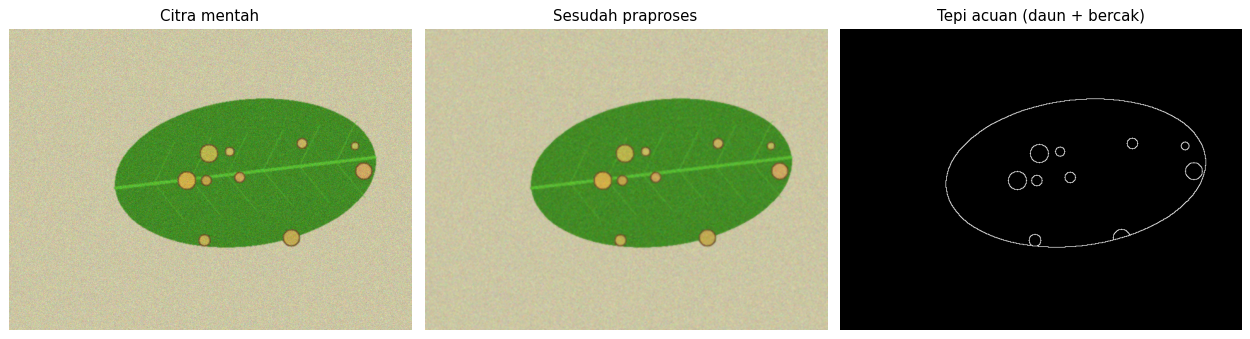

In [36]:
import importlib
import json
import utils_tepi

importlib.invalidate_caches()
importlib.reload(utils_tepi)

# Mengambil fungsi dari modul utils_tepi.py
tepi_acuan = utils_tepi.tepi_acuan
skor_tepi = utils_tepi.skor_tepi
iou = utils_tepi.iou
mask_daun_awal = utils_tepi.mask_daun_awal
bercak_awal = utils_tepi.bercak_awal

# Memuat parameter hasil Evaluasi P1-P4
with open("../hasil/param_praproses.json", "r") as f:
    PARAM_P5 = json.load(f)

# Menggunakan modul praproses.py yang sudah ada di P1-P4
import praproses as pp
importlib.reload(pp)

# Menggunakan fungsi muat() yang sudah tersedia sebelumnya
p5_img, p5_md, p5_mb = muat("teh_041.png")

# Praproses menggunakan parameter final P1-P4
p5_pra = pp.praproses(p5_img, PARAM_P5)

# Menggabungkan tepi daun dan tepi bercak sebagai acuan
p5_acuan = cv2.bitwise_or(
    tepi_acuan(p5_md),
    tepi_acuan(p5_mb)
)

tampil(
    [p5_img, p5_pra, p5_acuan],
    ["Citra mentah", "Sesudah praproses", "Tepi acuan (daun + bercak)"],
    ukuran=(14, 4)
)

Selisih maks gx manual vs cv2.Sobel: 0.0
Magnitudo maks: 510.6


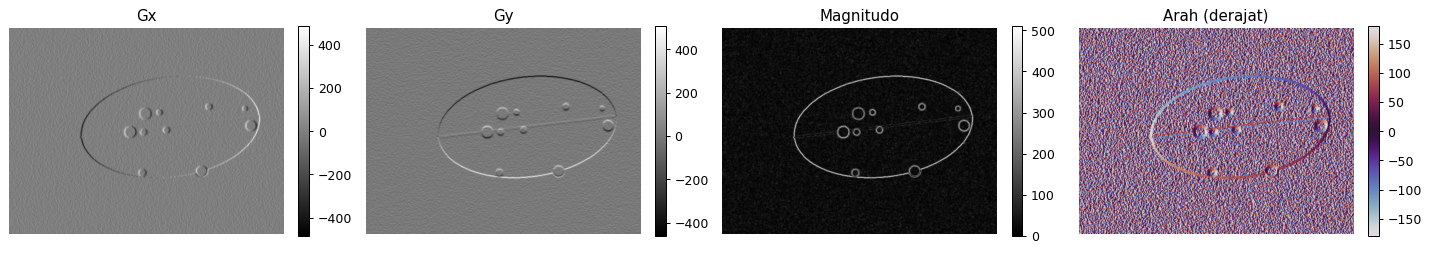

In [37]:
p5_g = p5_pra[:, :, 2].astype(np.float32)

p5_kx = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], np.float32)

p5_ky = p5_kx.T

# Gradien arah x dan y
p5_gx = cv2.filter2D(p5_g, cv2.CV_32F, p5_kx)
p5_gy = cv2.filter2D(p5_g, cv2.CV_32F, p5_ky)

# Magnitudo gradien dan arah gradien
p5_mag = np.sqrt(p5_gx ** 2 + p5_gy ** 2)
p5_arah = np.degrees(np.arctan2(p5_gy, p5_gx))

# Perbandingan dengan OpenCV
p5_gx_cv = cv2.Sobel(p5_g, cv2.CV_32F, 1, 0, ksize=3)

print(
    "Selisih maks gx manual vs cv2.Sobel:",
    np.abs(p5_gx - p5_gx_cv).max()
)

print("Magnitudo maks:", p5_mag.max().round(1))

# Panel visualisasi
plt.figure(figsize=(16, 3.6))

p5_panel_gradien = [
    (p5_gx, "Gx"),
    (p5_gy, "Gy"),
    (p5_mag, "Magnitudo"),
    (p5_arah, "Arah (derajat)")
]

for i, (citra, judul) in enumerate(p5_panel_gradien):
    plt.subplot(1, 4, i + 1)
    plt.imshow(
        citra,
        cmap="twilight" if i == 3 else "gray"
    )
    plt.title(judul)
    plt.axis("off")
    plt.colorbar(fraction=0.035)

plt.tight_layout()
plt.savefig("../hasil/p5_gradien_sobel.png", bbox_inches="tight")
plt.show()

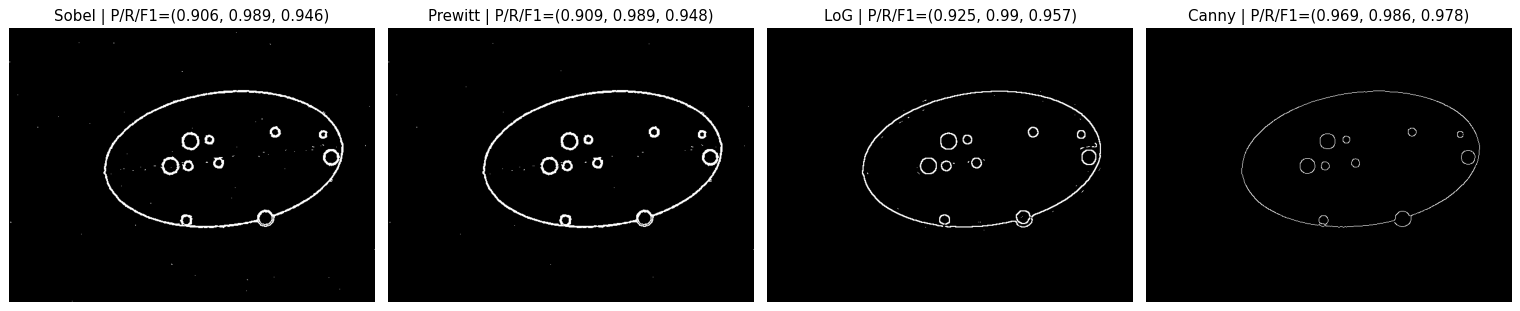

In [38]:
def tepi_sobel(g, T=100):
    g = g.astype(np.float32)

    m = np.hypot(
        cv2.Sobel(g, cv2.CV_32F, 1, 0),
        cv2.Sobel(g, cv2.CV_32F, 0, 1)
    )

    return ((m > T) * 255).astype(np.uint8)


def tepi_prewitt(g, T=75):
    kx = np.array([
        [-1, 0, 1],
        [-1, 0, 1],
        [-1, 0, 1]
    ], np.float32)

    g = g.astype(np.float32)

    m = np.hypot(
        cv2.filter2D(g, -1, kx),
        cv2.filter2D(g, -1, kx.T)
    )

    return ((m > T) * 255).astype(np.uint8)


def tepi_log(g, sigma=3.0, frac=0.2):
    """Laplacian of Gaussian: tepi = perlintasan nol yang cukup kuat."""

    L = cv2.Laplacian(
        cv2.GaussianBlur(
            g.astype(np.float32),
            (0, 0),
            sigma
        ),
        cv2.CV_32F
    )

    kernel = np.ones((3, 3), np.uint8)

    mn = cv2.erode(L, kernel)
    mx = cv2.dilate(L, kernel)

    ambang = frac * np.abs(L).max()

    return (
        ((mn < 0) & (mx > 0) & ((mx - mn) > ambang)) * 255
    ).astype(np.uint8)


def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g.astype(np.float32), (0, 0), sigma)

    # cv2.Canny requires an 8-bit input image (CV_8U)
    return cv2.Canny(g.clip(0, 255).astype(np.uint8), lo, hi)


# Daftar operator tepi
p5_metode = {
    "Sobel": tepi_sobel,
    "Prewitt": tepi_prewitt,
    "LoG": tepi_log,
    "Canny": tepi_canny
}

p5_hasil_operator = {
    nama: fungsi(p5_g)
    for nama, fungsi in p5_metode.items()
}

tampil(
    list(p5_hasil_operator.values()),
    [
        f"{nama} | P/R/F1={skor_tepi(hasil, p5_acuan)}"
        for nama, hasil in p5_hasil_operator.items()
    ],
    ukuran=(17, 4)
)

plt.savefig("../hasil/p5_panel_operator.png", bbox_inches="tight")
plt.show()

In [39]:
p5_baris_tepi = []

for _, d in label[label.kelas != "sehat"].iterrows():

    p5_img_i, p5_md_i, p5_mb_i = muat(d.nama_file)

    p5_ac = cv2.bitwise_or(
        tepi_acuan(p5_md_i),
        tepi_acuan(p5_mb_i)
    )

    p5_sumber = [
        ("mentah", p5_img_i),
        ("praproses", pp.praproses(p5_img_i, PARAM_P5))
    ]

    for p5_nama_sumber, p5_im in p5_sumber:

        p5_kanal = [
            (
                "Gray",
                cv2.cvtColor(p5_im, cv2.COLOR_BGR2GRAY)
            ),
            ("R", p5_im[:, :, 2])
        ]

        for p5_nama_kanal, p5_citra in p5_kanal:

            for p5_nama_metode, p5_fungsi in p5_metode.items():

                p5_p, p5_r, p5_f1 = skor_tepi(
                    p5_fungsi(p5_citra),
                    p5_ac
                )

                p5_baris_tepi.append([
                    d.kondisi_cahaya,
                    p5_nama_sumber,
                    p5_nama_kanal,
                    p5_nama_metode,
                    p5_p,
                    p5_r,
                    p5_f1
                ])


p5_tabel_tepi = pd.DataFrame(
    p5_baris_tepi,
    columns=[
        "kondisi",
        "sumber",
        "kanal",
        "metode",
        "P",
        "R",
        "F1"
    ]
)

p5_ringkas_tepi = (
    p5_tabel_tepi
    .groupby(["sumber", "kanal", "metode"])[["P", "R", "F1"]]
    .mean()
    .round(3)
)

print("Rerata presisi, recall, dan F1:")
display(p5_ringkas_tepi)

p5_tabel_tepi.to_csv(
    "../hasil/p5_tabel_tepi.csv",
    index=False
)

Rerata presisi, recall, dan F1:


P      R     F1
sumber    kanal metode                      
mentah    Gray  Canny    0.761  0.751  0.754
                LoG      0.600  0.999  0.740
                Prewitt  0.783  0.964  0.856
                Sobel    0.743  0.971  0.831
          R     Canny    0.990  0.982  0.985
                LoG      0.873  0.999  0.921
                Prewitt  0.487  0.998  0.605
                Sobel    0.421  0.998  0.538
praproses Gray  Canny    0.739  0.757  0.746
                LoG      0.599  0.999  0.740
                Prewitt  0.881  0.856  0.811
                Sobel    0.878  0.867  0.821
          R     Canny    0.989  0.978  0.983
                LoG      0.882  0.999  0.927
                Prewitt  0.872  0.989  0.918
                Sobel    0.854  0.990  0.905

metode,Canny,LoG,Prewitt,Sobel
kondisi,,,,
bayangan,0.991,0.949,0.935,0.924
gelap,0.991,0.975,0.833,0.816
kontras_rendah,0.948,0.809,0.972,0.972
normal,0.992,0.976,0.968,0.969
terang,0.992,0.929,0.880,0.845


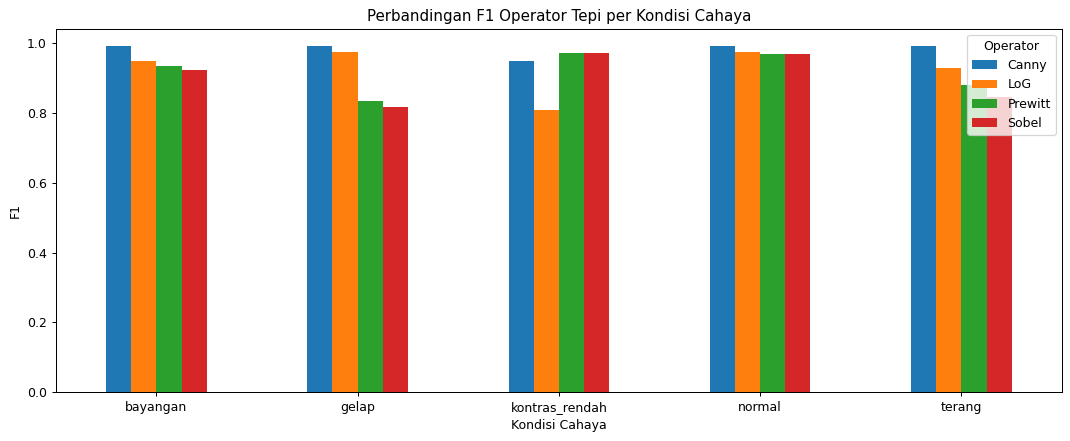

In [40]:
p5_f1_kondisi = (
    p5_tabel_tepi[
        (p5_tabel_tepi["sumber"] == "praproses") &
        (p5_tabel_tepi["kanal"] == "R")
    ]
    .groupby(["kondisi", "metode"])["F1"]
    .mean()
    .unstack()
)

display(p5_f1_kondisi.round(3))

p5_f1_kondisi.plot(
    kind="bar",
    figsize=(12, 5),
    rot=0
)

plt.title("Perbandingan F1 Operator Tepi per Kondisi Cahaya")
plt.xlabel("Kondisi Cahaya")
plt.ylabel("F1")
plt.legend(title="Operator")
plt.tight_layout()

plt.savefig("../hasil/p5_f1_kondisi.png", bbox_inches="tight")
plt.show()

In [41]:
p5_baris_canny = []

for _, d in label[label.kelas != "sehat"].iterrows():

    p5_img_i, p5_md_i, p5_mb_i = muat(d.nama_file)

    p5_g_i = pp.praproses(
        p5_img_i,
        PARAM_P5
    )[:, :, 2]

    p5_ad = tepi_acuan(p5_md_i)
    p5_ab = tepi_acuan(p5_mb_i)

    p5_ac = cv2.bitwise_or(p5_ad, p5_ab)

    for p5_sigma in [0, 1.0, 2.0]:

        for p5_lo, p5_hi in [
            (30, 90),
            (50, 150),
            (100, 200)
        ]:

            p5_e = tepi_canny(
                p5_g_i,
                p5_lo,
                p5_hi,
                p5_sigma
            )

            p5_p, p5_r, p5_f1 = skor_tepi(
                p5_e,
                p5_ac
            )

            p5_r_bercak = skor_tepi(
                p5_e,
                p5_ab
            )[1]

            p5_baris_canny.append([
                d.kelas,
                p5_sigma,
                f"{p5_lo}/{p5_hi}",
                p5_p,
                p5_r,
                p5_f1,
                p5_r_bercak
            ])


p5_tabel_canny = pd.DataFrame(
    p5_baris_canny,
    columns=[
        "kelas",
        "sigma",
        "ambang",
        "P",
        "R",
        "F1",
        "R_bercak"
    ]
)

print("Rerata hasil eksperimen Canny:")
display(
    p5_tabel_canny
    .groupby(["sigma", "ambang"])[
        ["P", "R", "F1", "R_bercak"]
    ]
    .mean()
    .round(3)
)

print("Recall bercak berdasarkan kelas:")
display(
    p5_tabel_canny.pivot_table(
        index=["sigma", "ambang"],
        columns="kelas",
        values="R_bercak"
    ).round(3)
)

p5_tabel_canny.to_csv(
    "../hasil/p5_eksperimen_canny.csv",
    index=False
)

Rerata hasil eksperimen Canny:


P      R     F1  R_bercak
sigma ambang                                
0.0   100/200  0.912  0.965  0.925     0.836
      30/90    0.144  0.998  0.202     0.984
      50/150   0.665  0.995  0.732     0.971
1.0   100/200  0.788  0.797  0.793     0.784
      30/90    0.757  0.997  0.824     0.984
      50/150   0.980  0.961  0.967     0.818
2.0   100/200  0.798  0.772  0.784     0.669
      30/90    0.989  0.978  0.983     0.887
      50/150   0.794  0.795  0.795     0.781

Recall bercak berdasarkan kelas:


kelas          berat  ringan
sigma ambang                
0.0   100/200  0.866   0.805
      30/90    0.990   0.978
      50/150   0.980   0.963
1.0   100/200  0.788   0.780
      30/90    0.988   0.981
      50/150   0.831   0.806
2.0   100/200  0.674   0.665
      30/90    0.906   0.869
      50/150   0.777   0.785

In [42]:
def canny_otomatis(g, s=0.33):
    """
    Ambang bawah = (1-s) x median.
    Ambang atas = (1+s) x median.
    """

    v = np.median(g)

    lo = int(max(0, (1 - s) * v))
    hi = int(min(255, (1 + s) * v))

    return cv2.Canny(g, lo, hi)


p5_baris_auto = []

for _, d in label[label.kelas != "sehat"].iterrows():

    p5_img_i, p5_md_i, p5_mb_i = muat(d.nama_file)

    p5_pra_i = pp.praproses(
        p5_img_i,
        PARAM_P5
    )

    p5_ac = cv2.bitwise_or(
        tepi_acuan(p5_md_i),
        tepi_acuan(p5_mb_i)
    )

    p5_kanal_auto = [
        (
            "Gray",
            cv2.cvtColor(p5_pra_i, cv2.COLOR_BGR2GRAY)
        ),
        ("R", p5_pra_i[:, :, 2])
    ]

    for p5_nama_kanal, p5_g_i in p5_kanal_auto:

        p5_median = np.median(p5_g_i)

        p5_f1_auto = skor_tepi(
            canny_otomatis(p5_g_i),
            p5_ac
        )[2]

        p5_f1_tetap = skor_tepi(
            tepi_canny(p5_g_i),
            p5_ac
        )[2]

        p5_baris_auto.append([
            d.kondisi_cahaya,
            p5_nama_kanal,
            "otomatis",
            p5_f1_auto,
            p5_median
        ])

        p5_baris_auto.append([
            d.kondisi_cahaya,
            p5_nama_kanal,
            "tetap 30/90",
            p5_f1_tetap,
            p5_median
        ])


p5_tabel_auto = pd.DataFrame(
    p5_baris_auto,
    columns=[
        "kondisi",
        "kanal",
        "ambang",
        "F1",
        "median"
    ]
)

print("F1 Canny otomatis dibandingkan ambang tetap:")
display(
    p5_tabel_auto.pivot_table(
        index=["kanal", "ambang"],
        columns="kondisi",
        values="F1"
    ).round(3)
)

print("Median intensitas berdasarkan kanal dan kondisi:")
display(
    p5_tabel_auto
    .groupby(["kanal", "kondisi"])["median"]
    .mean()
    .round(1)
)

p5_tabel_auto.to_csv(
    "../hasil/p5_canny_otomatis.csv",
    index=False
)

F1 Canny otomatis dibandingkan ambang tetap:


kondisi            bayangan  gelap  kontras_rendah  normal  terang
kanal ambang                                                      
Gray  otomatis        0.776  0.967           0.000   0.984   0.987
      tetap 30/90     0.911  0.917           0.000   0.951   0.950
R     otomatis        0.890  0.938           0.849   0.989   0.990
      tetap 30/90     0.991  0.991           0.948   0.992   0.992

Median intensitas berdasarkan kanal dan kondisi:


kanal  kondisi       
Gray   bayangan          111.2
       gelap             171.4
       kontras_rendah    160.4
       normal            194.1
       terang            207.8
R      bayangan          117.2
       gelap             187.4
       kontras_rendah    162.6
       normal            203.0
       terang            215.5
Name: median, dtype: float64

In [43]:
def canny_persentil(g, q, rasio=0.4, sigma=2.0):
    """
    Canny dengan ambang otomatis berdasarkan persentil magnitudo gradien.

    1. Gaussian Blur
    2. Menghitung magnitudo Sobel
    3. Ambang atas menggunakan persentil q
    4. Ambang bawah = rasio x ambang atas
    5. Menjalankan Canny
    """

    g = np.asarray(g, dtype=np.uint8)

    # 1. Gaussian Blur
    if sigma > 0:
        g_blur = cv2.GaussianBlur(
            g,
            (0, 0),
            sigma
        )
    else:
        g_blur = g.copy()

    # 2. Magnitudo gradien Sobel
    gx = cv2.Sobel(
        g_blur.astype(np.float32),
        cv2.CV_32F,
        1,
        0,
        ksize=3
    )

    gy = cv2.Sobel(
        g_blur.astype(np.float32),
        cv2.CV_32F,
        0,
        1,
        ksize=3
    )

    mag = np.hypot(gx, gy)

    # 3. Menentukan ambang
    ambang_atas = float(np.percentile(mag, q))
    ambang_bawah = float(rasio * ambang_atas)

    ambang_atas = max(1, int(round(ambang_atas)))
    ambang_bawah = max(0, int(round(ambang_bawah)))

    # 4. Deteksi Canny
    hasil = cv2.Canny(
        g_blur,
        ambang_bawah,
        ambang_atas
    )

    return hasil

In [44]:
p5_baris_persentil = []

for _, d in label[label.kelas != "sehat"].iterrows():

    p5_img_i, p5_md_i, p5_mb_i = muat(d.nama_file)

    p5_pra_i = pp.praproses(
        p5_img_i,
        PARAM_P5
    )

    p5_ac = cv2.bitwise_or(
        tepi_acuan(p5_md_i),
        tepi_acuan(p5_mb_i)
    )

    p5_kanal_i = [
        (
            "Gray",
            cv2.cvtColor(p5_pra_i, cv2.COLOR_BGR2GRAY)
        ),
        ("R", p5_pra_i[:, :, 2])
    ]

    for p5_nama_kanal, p5_g_i in p5_kanal_i:

        for p5_q in [90, 95, 98]:

            p5_hasil = canny_persentil(
                p5_g_i,
                q=p5_q,
                rasio=0.4,
                sigma=2.0
            )

            p5_p, p5_r, p5_f1 = skor_tepi(
                p5_hasil,
                p5_ac
            )

            p5_baris_persentil.append([
                d.kelas,
                d.kondisi_cahaya,
                p5_nama_kanal,
                p5_q,
                p5_p,
                p5_r,
                p5_f1
            ])


p5_tabel_persentil = pd.DataFrame(
    p5_baris_persentil,
    columns=[
        "kelas",
        "kondisi",
        "kanal",
        "q",
        "P",
        "R",
        "F1"
    ]
)

print("Rerata F1 berdasarkan persentil:")
display(
    p5_tabel_persentil
    .groupby(["kanal", "q"])[["P", "R", "F1"]]
    .mean()
    .round(3)
)

print("F1 berdasarkan persentil dan kondisi cahaya:")
display(
    p5_tabel_persentil.pivot_table(
        index=["kanal", "q"],
        columns="kondisi",
        values="F1"
    ).round(3)
)

p5_tabel_persentil.to_csv(
    "../hasil/p5_canny_persentil.csv",
    index=False
)

Rerata F1 berdasarkan persentil:


P      R     F1
kanal q                      
Gray  90  0.039  0.953  0.074
      95  0.286  0.952  0.396
      98  0.761  0.948  0.835
R     90  0.040  0.997  0.076
      95  0.216  0.997  0.303
      98  0.987  0.996  0.991

F1 berdasarkan persentil dan kondisi cahaya:


kondisi   bayangan  gelap  kontras_rendah  normal  terang
kanal q                                                  
Gray  90     0.075  0.110           0.054   0.072   0.059
      95     0.447  0.558           0.194   0.499   0.279
      98     0.758  0.852           0.839   0.845   0.879
R     90     0.073  0.125           0.062   0.064   0.057
      95     0.336  0.380           0.179   0.440   0.182
      98     0.978  0.995           0.996   0.994   0.992

kanal,Gray,R
kondisi,,
bayangan,255.5,0.0
gelap,0.0,0.0
kontras_rendah,0.0,0.0
normal,0.0,0.0
terang,0.0,0.0


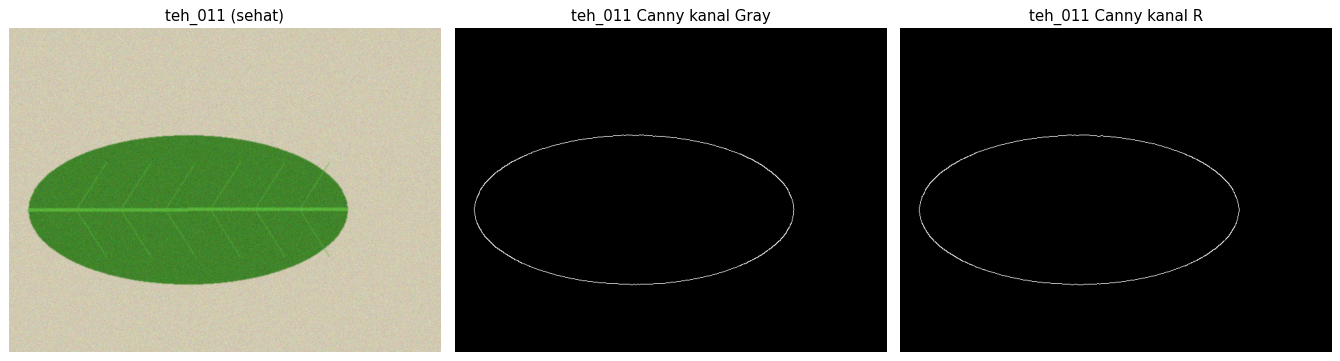

In [45]:
p5_baris_sehat = []
p5_panel_sehat = []
p5_judul_sehat = []

for _, d in label[label.kelas == "sehat"].iterrows():

    p5_img_i, p5_md_i, p5_mb_i = muat(d.nama_file)

    p5_pra_i = pp.praproses(
        p5_img_i,
        PARAM_P5
    )

    # Bagian dalam daun
    p5_dalam = (
        cv2.erode(
            p5_md_i,
            np.ones((7, 7), np.uint8)
        ) > 0
    )

    p5_kanal_i = [
        (
            "Gray",
            cv2.cvtColor(p5_pra_i, cv2.COLOR_BGR2GRAY)
        ),
        ("R", p5_pra_i[:, :, 2])
    ]

    for p5_nama_kanal, p5_g_i in p5_kanal_i:

        p5_e = tepi_canny(p5_g_i)

        p5_jumlah_tepi = int(
            ((p5_e > 0) & p5_dalam).sum()
        )

        p5_baris_sehat.append([
            d.kondisi_cahaya,
            p5_nama_kanal,
            p5_jumlah_tepi
        ])

        if d.nama_file == "teh_011.png":
            p5_panel_sehat.append(p5_e)
            p5_judul_sehat.append(
                f"teh_011 Canny kanal {p5_nama_kanal}"
            )


p5_tabel_sehat = pd.DataFrame(
    p5_baris_sehat,
    columns=[
        "kondisi",
        "kanal",
        "piksel_tepi_di_dalam_daun"
    ]
)

display(
    p5_tabel_sehat.pivot_table(
        index="kondisi",
        columns="kanal",
        values="piksel_tepi_di_dalam_daun"
    ).round(1)
)

# Panel visualisasi
p5_img_sehat = muat("teh_011.png")[0]

tampil(
    [p5_img_sehat] + p5_panel_sehat,
    ["teh_011 (sehat)"] + p5_judul_sehat,
    ukuran=(15, 4)
)

p5_tabel_sehat.to_csv(
    "../hasil/p5_tepi_daun_sehat.csv",
    index=False
)

plt.savefig(
    "../hasil/p5_tepi_daun_sehat.png",
    bbox_inches="tight"
)
plt.show()

In [46]:
p5_tabel_keputusan = pd.DataFrame([
    [
        "Menemukan batas daun",
        "",
        "",
        ""
    ],
    [
        "Menemukan batas bercak",
        "",
        "",
        ""
    ],
    [
        "Mengisi wilayah bercak (segmentasi)",
        "",
        "",
        ""
    ],
    [
        "Fitur bentuk bercak (P9)",
        "",
        "",
        ""
    ]
], columns=[
    "Keperluan",
    "Dipakai? (ya/tidak)",
    "Operator dan parameter",
    "Bukti (tabel atau gambar)"
])

display(p5_tabel_keputusan)

p5_tabel_keputusan.to_csv(
    "../hasil/p5_keputusan_tepi.csv",
    index=False
)

,Keperluan,Dipakai? (ya/tidak),Operator dan parameter,Bukti (tabel atau gambar)
0,Menemukan batas daun,,,
1,Menemukan batas bercak,,,
2,Mengisi wilayah bercak (segmentasi),,,
3,Fitur bentuk bercak (P9),,,
